# Solving Durablemodel with Search in infinite horizon

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
from pathlib import Path

start_time = time.time()

from DurableModel import DurableConsumer
from HARK.ConsumptionSaving.ConsIndShockModel import utility_inv

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.3,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=5.0,
    nNrmCount=100,
    mNrmMax=8.0,
    mNrmCount=100,
    xNrmMax=13.0,
    xNrmCount=200,
    aNrmMax=8.0,
    aNrmCount=100,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-6,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=300,  # iteration cap for cycles=0 (matches background max_cycles)
    verbose=False,
)


In [3]:
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_eps"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["PriceShkCount"] = 1
base_search["SearchCost"] = 0.2
base_search["cycle"] = 0

search_model = DurableConsumer(**base_search)
search_model.update()
search_model.solve()

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:503: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:510: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:510: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha

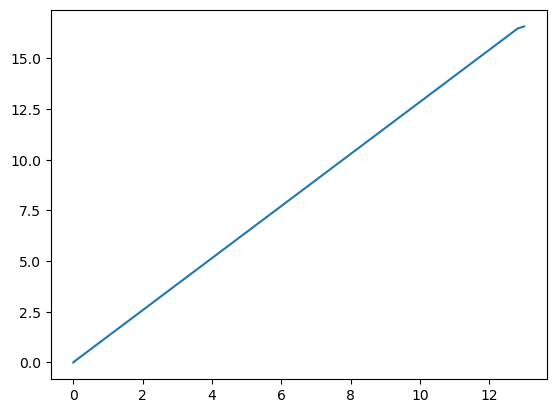

In [4]:
plt.plot(search_model.xNrmGrid, search_model.solution[0].cFuncAdj(search_model.xNrmGrid))